# Book Market Analytics – Books to Scrape
**Module:** Data Science 512
**Student:** Cado
**Goal:** Scrape, clean, visualise and model book pricesimport requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BASE_URL = "https://books.toscrape.com/catalogue/"
print("Setup complete ✅")

In [12]:
import pd
import plt
import requests

url = "https://books.toscrape.com/catalogue/page-1.html"
response = requests.get(url)

print("Status code:", response.status_code)

Status code: 200


NameError: name 'pd' is not defined

NameError: name 'pd' is not defined

In [3]:
soup = BeautifulSoup(response.text, "html.parser")

books = soup.find_all("article", class_="product_pod")

print("Books found on this page:", len(books))

Books found on this page: 20


In [4]:
book = books[0]   # the first book only

title = book.h3.a["title"]
price = book.find("p", class_="price_color").text

print("Title:", title)
print("Price:", price)

Title: A Light in the Attic
Price: Â£51.77


In [5]:
rating = book.find("p", class_="star-rating")["class"][1]
stock = book.find("p", class_="instock availability").text.strip()

print("Rating:", rating)
print("Stock:", stock)

Rating: Three
Stock: In stock


In [6]:
page_data = []

for book in books:
    title = book.h3.a["title"]
    price = book.find("p", class_="price_color").text
    rating = book.find("p", class_="star-rating")["class"][1]
    stock = book.find("p", class_="instock availability").text.strip()
    link = book.h3.a["href"]

    page_data.append({
        "title": title,
        "price": price,
        "rating": rating,
        "stock": stock,
        "link": link
    })

df_test = pd.DataFrame(page_data)
df_test.head()

,title,price,rating,stock,link
0,A Light in the Attic,Â£51.77,Three,In stock,a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,Â£53.74,One,In stock,tipping-the-velvet_999/index.html
2,Soumission,Â£50.10,One,In stock,soumission_998/index.html
3,Sharp Objects,Â£47.82,Four,In stock,sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...


In [7]:
all_books = []

for page in range(1, 51):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    response = requests.get(url)
    response.encoding = "utf-8"   # fixes the Â£ problem
    soup = BeautifulSoup(response.text, "html.parser")

    books = soup.find_all("article", class_="product_pod")

    for book in books:
        all_books.append({
            "title": book.h3.a["title"],
            "price": book.find("p", class_="price_color").text,
            "rating": book.find("p", class_="star-rating")["class"][1],
            "stock": book.find("p", class_="instock availability").text.strip(),
            "link": book.h3.a["href"]
        })

    print(f"Page {page} done ✅")
    time.sleep(0.5)   # be polite to the website

print("Total books scraped:", len(all_books))

Page 1 done ✅
Page 2 done ✅
Page 3 done ✅
Page 4 done ✅
Page 5 done ✅
Page 6 done ✅
Page 7 done ✅
Page 8 done ✅
Page 9 done ✅
Page 10 done ✅
Page 11 done ✅
Page 12 done ✅
Page 13 done ✅
Page 14 done ✅
Page 15 done ✅
Page 16 done ✅
Page 17 done ✅
Page 18 done ✅
Page 19 done ✅
Page 20 done ✅
Page 21 done ✅
Page 22 done ✅
Page 23 done ✅
Page 24 done ✅
Page 25 done ✅
Page 26 done ✅
Page 27 done ✅
Page 28 done ✅
Page 29 done ✅
Page 30 done ✅
Page 31 done ✅
Page 32 done ✅
Page 33 done ✅
Page 34 done ✅
Page 35 done ✅
Page 36 done ✅
Page 37 done ✅
Page 38 done ✅
Page 39 done ✅
Page 40 done ✅
Page 41 done ✅
Page 42 done ✅
Page 43 done ✅
Page 44 done ✅
Page 45 done ✅
Page 46 done ✅
Page 47 done ✅
Page 48 done ✅
Page 49 done ✅
Page 50 done ✅
Total books scraped: 1000


In [15]:
df = pd.DataFrame(all_books)

print("Shape:", df.shape)
df.head()

Shape: (1000, 5)


,title,price,rating,stock,link
0,A Light in the Attic,£51.77,Three,In stock,a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,£53.74,One,In stock,tipping-the-velvet_999/index.html
2,Soumission,£50.10,One,In stock,soumission_998/index.html
3,Sharp Objects,£47.82,Four,In stock,sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...


In [16]:
test_link = df["link"][0]
test_url = BASE_URL + test_link

r = requests.get(test_url)
r.encoding = "utf-8"
soup = BeautifulSoup(r.text, "html.parser")

# Genre (3rd item in the breadcrumb)
category = soup.find("ul", class_="breadcrumb").find_all("li")[2].text.strip()

# Description (may be missing for some books)
desc_tag = soup.find("div", id="product_description")
description = desc_tag.find_next_sibling("p").text if desc_tag else None

# Product information table
table = {}
for row in soup.find("table", class_="table-striped").find_all("tr"):
    table[row.th.text] = row.td.text

print("Category:", category)
print("Description:", description[:80], "...")
print("Availability:", table["Availability"])
print("Reviews:", table["Number of reviews"])

Category: Poetry
Description: It's hard to imagine a world without A Light in the Attic. This now-classic coll ...
Availability: In stock (22 available)
Reviews: 0


In [17]:
def get_details(link):
    url = BASE_URL + link
    r = requests.get(url)
    r.encoding = "utf-8"
    soup = BeautifulSoup(r.text, "html.parser")

    category = soup.find("ul", class_="breadcrumb").find_all("li")[2].text.strip()

    desc_tag = soup.find("div", id="product_description")
    description = desc_tag.find_next_sibling("p").text if desc_tag else None

    table = {}
    for row in soup.find("table", class_="table-striped").find_all("tr"):
        table[row.th.text] = row.td.text

    return {
        "category": category,
        "description": description,
        "upc": table.get("UPC"),
        "availability": table.get("Availability"),
        "num_reviews": table.get("Number of reviews"),
        "price_excl_tax": table.get("Price (excl. tax)"),
        "price_incl_tax": table.get("Price (incl. tax)")
    }

# Test it on the first 3 books
for i in range(3):
    print(get_details(df["link"][i]))
    print("-----")

{'category': 'Poetry', 'description': "It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love th It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love that Silverstein. Need proof of his genius? RockabyeRockabye baby, in the treetopDon't you know a treetopIs no safe place to rock?And who put you up there,And your cradle, too?Baby, I think someone down here'sGot

In [18]:
details = []

for i, link in enumerate(df["link"]):
    try:
        details.append(get_details(link))
    except Exception as e:
        print(f"⚠️ Problem with book {i}: {e}")
        details.append({})   # keeps the rows lined up

    if (i + 1) % 50 == 0:
        print(f"{i + 1} / 1000 done ✅")

    time.sleep(0.3)

print("Finished! Details collected:", len(details))

50 / 1000 done ✅
100 / 1000 done ✅
150 / 1000 done ✅
200 / 1000 done ✅
250 / 1000 done ✅
300 / 1000 done ✅
350 / 1000 done ✅
400 / 1000 done ✅
450 / 1000 done ✅
500 / 1000 done ✅
550 / 1000 done ✅
600 / 1000 done ✅
650 / 1000 done ✅
700 / 1000 done ✅
750 / 1000 done ✅
800 / 1000 done ✅
850 / 1000 done ✅
900 / 1000 done ✅
950 / 1000 done ✅
1000 / 1000 done ✅
Finished! Details collected: 1000


In [19]:
df_details = pd.DataFrame(details)

df_raw = pd.concat([df, df_details], axis=1)

print("Shape:", df_raw.shape)
df_raw.head()

Shape: (1000, 12)


,title,price,rating,stock,link,category,description,upc,availability,num_reviews,price_excl_tax,price_incl_tax
0,A Light in the Attic,£51.77,Three,In stock,a-light-in-the-attic_1000/index.html,Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,In stock (22 available),0,£51.77,£51.77
1,Tipping the Velvet,£53.74,One,In stock,tipping-the-velvet_999/index.html,Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,In stock (20 available),0,£53.74,£53.74
2,Soumission,£50.10,One,In stock,soumission_998/index.html,Fiction,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,In stock (20 available),0,£50.10,£50.10
3,Sharp Objects,£47.82,Four,In stock,sharp-objects_997/index.html,Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,In stock (20 available),0,£47.82,£47.82
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...,History,From a renowned historian comes a groundbreaki...,4165285e1663650f,In stock (20 available),0,£54.23,£54.23


In [20]:
df_raw.to_csv("books_raw.csv", index=False, encoding="utf-8-sig")

print("Saved books_raw.csv ✅")

Saved books_raw.csv ✅


In [21]:
df_clean = df_raw.copy()   # work on a copy, keep the raw safe

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   title           1000 non-null   str  
 1   price           1000 non-null   str  
 2   rating          1000 non-null   str  
 3   stock           1000 non-null   str  
 4   link            1000 non-null   str  
 5   category        1000 non-null   str  
 6   description     998 non-null    str  
 7   upc             1000 non-null   str  
 8   availability    1000 non-null   str  
 9   num_reviews     1000 non-null   str  
 10  price_excl_tax  1000 non-null   str  
 11  price_incl_tax  1000 non-null   str  
dtypes: str(12)
memory usage: 93.9 KB


In [22]:
df_clean["price"] = (
    df_clean["price"]
    .str.replace("£", "", regex=False)
    .str.replace("Â", "", regex=False)
    .astype(float)
)

print(df_clean["price"].describe())


count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price, dtype: float64


In [23]:
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

df_clean["rating_num"] = df_clean["rating"].map(rating_map)

print(df_clean["rating_num"].value_counts().sort_index())
print("Missing ratings:", df_clean["rating_num"].isna().sum())

rating_num
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64
Missing ratings: 0


In [ ]:
# Quantity: grab the number inside the brackets
df_clean["stock_qty"] = (
    df_clean["availability"]
    .str.extract(r"\((\d+) available\)")[0]
    .astype(float)
)

# In stock flag: 1 = in stock, 0 = out of stock
df_clean["in_stock"] = df_clean["availability"].str.contains("In stock").astype(int)

print(df_clean[["availability", "stock_qty", "in_stock"]].head())
print("Missing quantities:", df_clean["stock_qty"].isna().sum())
print(df_clean["in_stock"].value_counts())

In [24]:
# Number of reviews: text → number
df_clean["num_reviews"] = pd.to_numeric(df_clean["num_reviews"], errors="coerce")

# Tax-price columns: remove £ and convert to numbers
for col in ["price_excl_tax", "price_incl_tax"]:
    df_clean[col] = (
        df_clean[col]
        .str.replace("£", "", regex=False)
        .str.replace("Â", "", regex=False)
        .astype(float)
    )

print(df_clean[["price", "price_excl_tax", "price_incl_tax", "num_reviews"]].describe())

            price  price_excl_tax  price_incl_tax  num_reviews
count  1000.00000      1000.00000      1000.00000       1000.0
mean     35.07035        35.07035        35.07035          0.0
std      14.44669        14.44669        14.44669          0.0
min      10.00000        10.00000        10.00000          0.0
25%      22.10750        22.10750        22.10750          0.0
50%      35.98000        35.98000        35.98000          0.0
75%      47.45750        47.45750        47.45750          0.0
max      59.99000        59.99000        59.99000          0.0


In [25]:
print("Missing values per column:")
print(df_clean.isna().sum())

# Fill missing descriptions with a clear label
df_clean["has_description"] = df_clean["description"].notna().astype(int)
df_clean["description"] = df_clean["description"].fillna("No description available")

print("\nAfter fixing:")
print("Missing descriptions:", (df_clean["description"] == "No description available").sum())

Missing values per column:
title             0
price             0
rating            0
stock             0
link              0
category          0
description       2
upc               0
availability      0
num_reviews       0
price_excl_tax    0
price_incl_tax    0
rating_num        0
dtype: int64

After fixing:
Missing descriptions: 2


In [26]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate UPC codes:", df_clean["upc"].duplicated().sum())
print("Duplicate titles:", df_clean["title"].duplicated().sum())

df_clean = df_clean.drop_duplicates(subset="upc").reset_index(drop=True)

print("Rows after removing duplicates:", len(df_clean))

Duplicate rows: 0
Duplicate UPC codes: 0
Duplicate titles: 1
Rows after removing duplicates: 1000


In [27]:
# Tidy the text: remove extra spaces
df_clean["title"] = df_clean["title"].str.strip()
df_clean["description"] = df_clean["description"].str.strip()
df_clean["category"] = df_clean["category"].str.strip()

# New numeric features from text
df_clean["title_length"] = df_clean["title"].str.len()
df_clean["title_words"] = df_clean["title"].str.split().str.len()
df_clean["desc_length"] = df_clean["description"].str.len()
df_clean["desc_words"] = df_clean["description"].str.split().str.len()

print(df_clean[["title_length", "title_words", "desc_length", "desc_words"]].describe())

       title_length  title_words  desc_length   desc_words
count   1000.000000  1000.000000  1000.000000  1000.000000
mean      39.097000     6.735000  1431.676000   236.381000
std       25.752724     4.204337   669.222377   107.551267
min        2.000000     1.000000    24.000000     3.000000
25%       19.000000     3.000000  1069.750000   177.000000
50%       35.000000     6.000000  1348.500000   222.500000
75%       53.000000     9.000000  1681.500000   279.000000
max      204.000000    27.000000  8646.000000  1390.000000


In [28]:
print("Number of categories:", df_clean["category"].nunique())
print()
print(df_clean["category"].value_counts())

Number of categories: 50

category
Default               152
Nonfiction            110
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Poetry                 19
Classics               19
History                18
Horror                 17
Womens Fiction         17
Science Fiction        16
Science                14
Music                  13
Business               12
Travel                 11
Thriller               11
Philosophy             11
Humor                  10
Autobiography           9
Art                     8
Religion                7
Psychology              7
Spirituality            6
New Adult               6
Christian Fiction       6
Self Help               5
Biography               5
Sports and Games        5
Health                  4
Politics                3
Con

In [29]:
top_10 = df_clean["category"].value_counts().head(10).index

df_clean["category_grouped"] = df_clean["category"].where(
    df_clean["category"].isin(top_10), "Other"
)

print(df_clean["category_grouped"].value_counts())

category_grouped
Other             332
Default           152
Nonfiction        110
Sequential Art     75
Add a comment      67
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Name: count, dtype: int64


In [30]:
# Final look
df_clean.info()
print()
print("Missing values left:", df_clean.isna().sum().sum())

# Save the clean dataset
df_clean.to_csv("books_clean.csv", index=False, encoding="utf-8-sig")
print("Saved books_clean.csv ✅")

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   title             1000 non-null   str    
 1   price             1000 non-null   float64
 2   rating            1000 non-null   str    
 3   stock             1000 non-null   str    
 4   link              1000 non-null   str    
 5   category          1000 non-null   str    
 6   description       1000 non-null   str    
 7   upc               1000 non-null   str    
 8   availability      1000 non-null   str    
 9   num_reviews       1000 non-null   int64  
 10  price_excl_tax    1000 non-null   float64
 11  price_incl_tax    1000 non-null   float64
 12  rating_num        1000 non-null   int64  
 13  has_description   1000 non-null   int64  
 14  title_length      1000 non-null   int64  
 15  title_words       1000 non-null   int64  
 16  desc_length       1000 non-null   int64  
 17  desc_wo

In [9]:
sns.set_style("whitegrid")

plt.figure(figsize=(8, 5))
plt.hist(df_clean["price"], bins=20, color="steelblue", edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of books")
plt.axvline(df_clean["price"].mean(), color="red", linestyle="--", label="Mean")
plt.legend()
plt.show()

print("Mean price:", round(df_clean["price"].mean(), 2))
print("Median price:", round(df_clean["price"].median(), 2))

NameError: name 'sns' is not defined

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df_clean = pd.read_csv("books_clean.csv")

print("Shape:", df_clean.shape)
df_clean.head()

Shape: (1000, 19)


,title,price,rating,stock,link,category,description,upc,availability,num_reviews,price_excl_tax,price_incl_tax,rating_num,has_description,title_length,title_words,desc_length,desc_words,category_grouped
0,A Light in the Attic,51.77,Three,In stock,a-light-in-the-attic_1000/index.html,Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,In stock (22 available),0,51.77,51.77,3,1,20,5,1017,164,Other
1,Tipping the Velvet,53.74,One,In stock,tipping-the-velvet_999/index.html,Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,In stock (20 available),0,53.74,53.74,1,1,18,3,1029,165,Other
2,Soumission,50.10,One,In stock,soumission_998/index.html,Fiction,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,In stock (20 available),0,50.10,50.10,1,1,10,1,1093,163,Fiction
3,Sharp Objects,47.82,Four,In stock,sharp-objects_997/index.html,Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,In stock (20 available),0,47.82,47.82,4,1,13,2,1635,274,Mystery
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...,History,From a renowned historian comes a groundbreaki...,4165285e1663650f,In stock (20 available),0,54.23,54.23,5,1,37,6,1945,304,Other


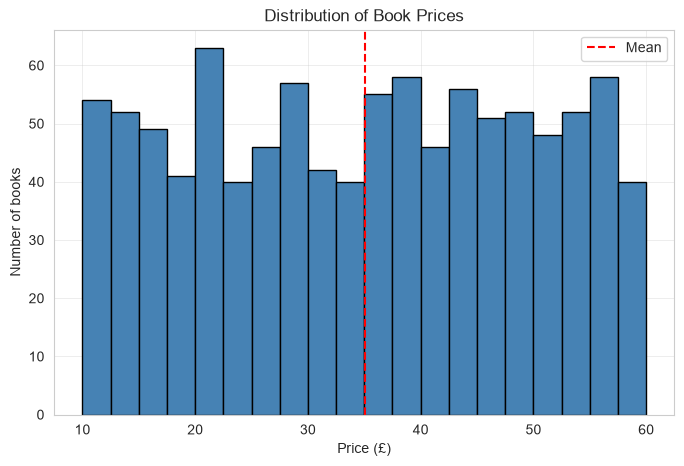

Mean price: 35.07
Median price: 35.98


In [14]:
sns.set_style("whitegrid")

plt.figure(figsize=(8, 5))
plt.hist(df_clean["price"], bins=20, color="steelblue", edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of books")
plt.axvline(df_clean["price"].mean(), color="red", linestyle="--", label="Mean")
plt.legend()
plt.show()

print("Mean price:", round(df_clean["price"].mean(), 2))
print("Median price:", round(df_clean["price"].median(), 2))

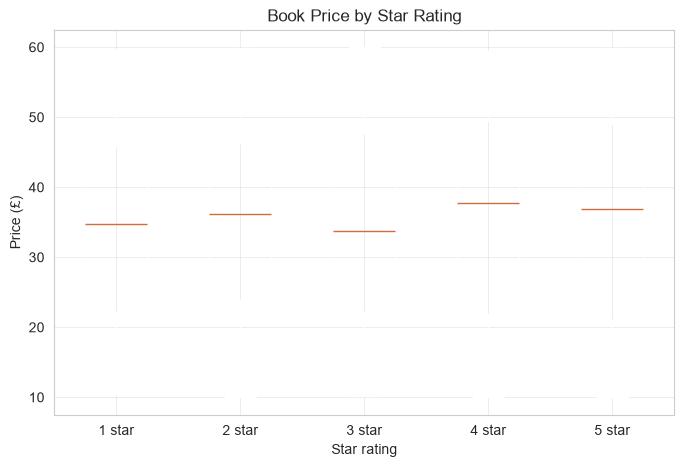

rating_num
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: price, dtype: float64


In [15]:
groups = [df_clean[df_clean["rating_num"] == r]["price"] for r in [1, 2, 3, 4, 5]]

plt.figure(figsize=(8, 5))
plt.boxplot(groups, tick_labels=["1 star", "2 star", "3 star", "4 star", "5 star"])
plt.title("Book Price by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Price (£)")
plt.show()

print(df_clean.groupby("rating_num")["price"].mean().round(2))

**Insight:** Average prices are very similar across all star ratings, so rating does not appear to strongly influence price.


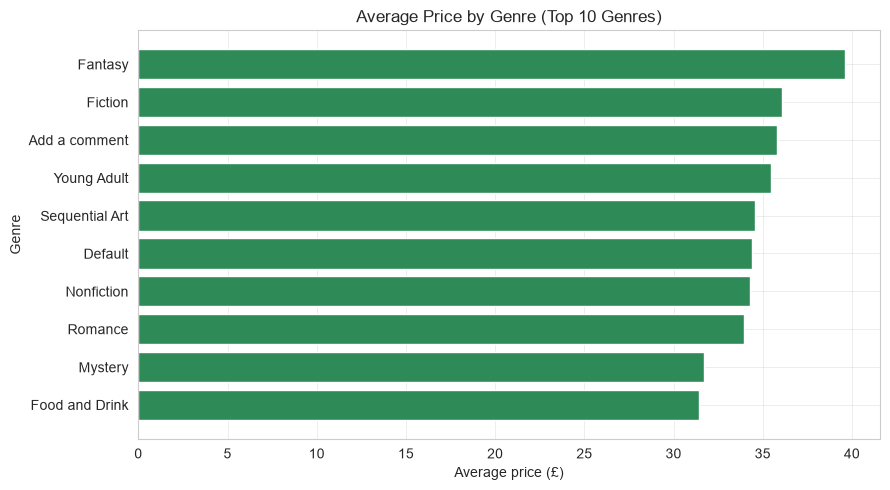

category
Food and Drink    31.41
Mystery           31.72
Romance           33.93
Nonfiction        34.26
Default           34.39
Sequential Art    34.57
Young Adult       35.45
Add a comment     35.80
Fiction           36.07
Fantasy           39.59
Name: price, dtype: float64


In [16]:
top_10 = df_clean["category"].value_counts().head(10).index
subset = df_clean[df_clean["category"].isin(top_10)]

avg_price = subset.groupby("category")["price"].mean().sort_values()

plt.figure(figsize=(9, 5))
plt.barh(avg_price.index, avg_price.values, color="seagreen")
plt.title("Average Price by Genre (Top 10 Genres)")
plt.xlabel("Average price (£)")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

print(avg_price.round(2))

**Insight:** [Genre] has the highest average price (£__), while [Genre] is the cheapest (£__). Genre appears to have [a small / a noticeable] effect on price.

KeyError: 'stock_qty'

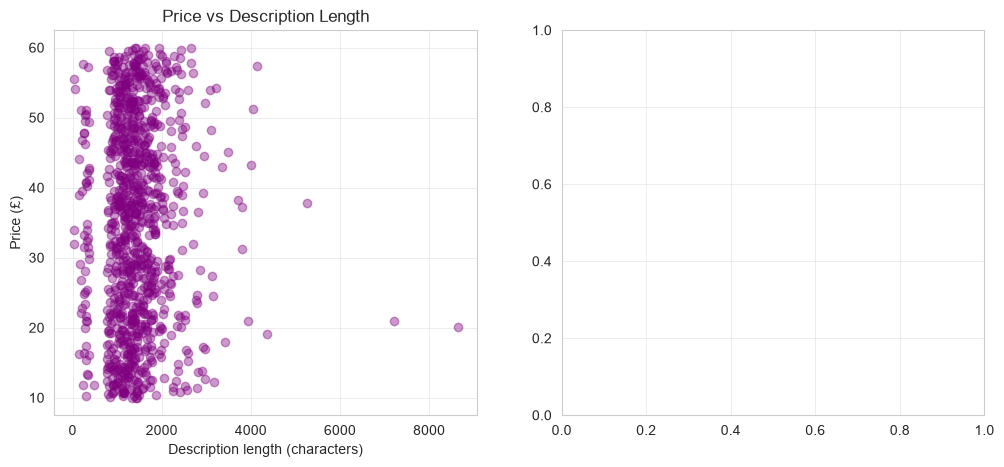

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(df_clean["desc_length"], df_clean["price"], alpha=0.4, color="purple")
ax[0].set_title("Price vs Description Length")
ax[0].set_xlabel("Description length (characters)")
ax[0].set_ylabel("Price (£)")

ax[1].scatter(df_clean["stock_qty"], df_clean["price"], alpha=0.4, color="orange")
ax[1].set_title("Price vs Stock Quantity")
ax[1].set_xlabel("Stock quantity")
ax[1].set_ylabel("Price (£)")

plt.tight_layout()
plt.savefig("scatter_charts.png", dpi=150)   # save BEFORE show
plt.show()

print("Correlation with price:")
print(df_clean[["desc_length", "stock_qty"]].corrwith(df_clean["price"]).round(3))

**Insight:** The scatter plots show [no clear / a weak / a clear] pattern. Correlations close to 0 (such as 0.02) mean there is almost no linear relationship with price.

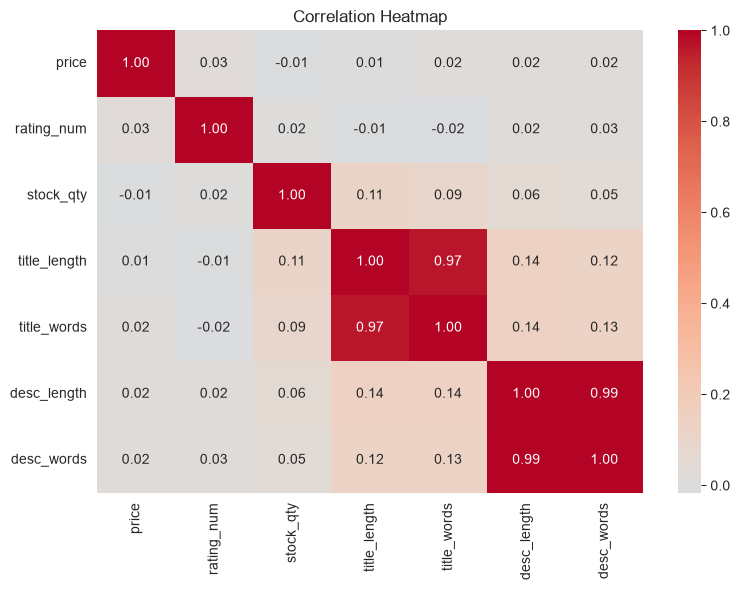

In [25]:
num_cols = ["price", "rating_num", "stock_qty", "title_length",
            "title_words", "desc_length", "desc_words"]

corr = df_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150)   # save BEFORE show
plt.show()

In [20]:
print(list(df_clean.columns))

missing = [c for c in num_cols if c not in df_clean.columns]
print("Missing columns:", missing)

['title', 'price', 'rating', 'stock', 'link', 'category', 'description', 'upc', 'availability', 'num_reviews', 'price_excl_tax', 'price_incl_tax', 'rating_num', 'has_description', 'title_length', 'title_words', 'desc_length', 'desc_words', 'category_grouped']
Missing columns: ['stock_qty']


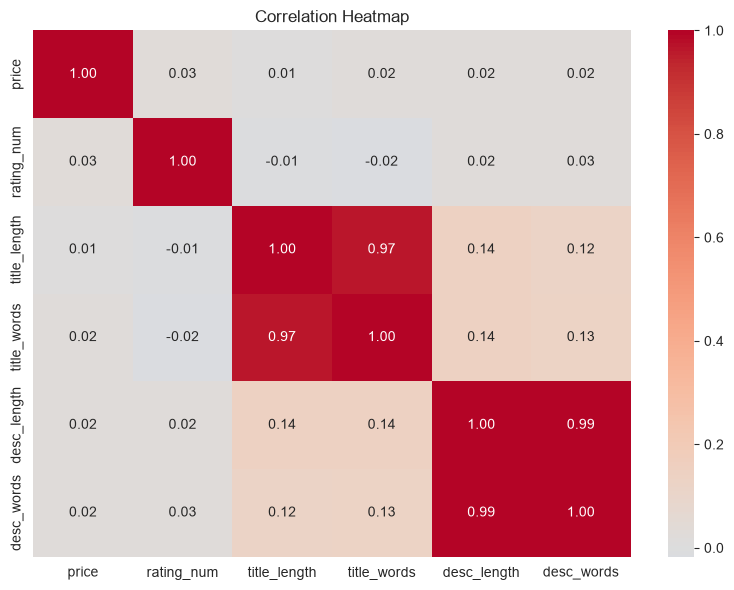

In [21]:
num_cols = [c for c in num_cols if c in df_clean.columns]

corr = df_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150)   # save BEFORE show
plt.show()

In [22]:
print("Columns in df_clean:")
print(list(df_clean.columns))
print()
print("Shape:", df_clean.shape)

Columns in df_clean:
['title', 'price', 'rating', 'stock', 'link', 'category', 'description', 'upc', 'availability', 'num_reviews', 'price_excl_tax', 'price_incl_tax', 'rating_num', 'has_description', 'title_length', 'title_words', 'desc_length', 'desc_words', 'category_grouped']

Shape: (1000, 19)


In [23]:
df_clean["stock_qty"] = (
    df_clean["availability"]
    .str.extract(r"\((\d+) available\)")[0]
    .astype(float)
)

df_clean["in_stock"] = df_clean["availability"].str.contains("In stock").astype(int)

print(df_clean[["availability", "stock_qty", "in_stock"]].head())
print("Missing quantities:", df_clean["stock_qty"].isna().sum())

# Save the fixed dataset
df_clean.to_csv("books_clean.csv", index=False, encoding="utf-8-sig")
print("Saved books_clean.csv ✅  Shape:", df_clean.shape)

              availability  stock_qty  in_stock
0  In stock (22 available)       22.0         1
1  In stock (20 available)       20.0         1
2  In stock (20 available)       20.0         1
3  In stock (20 available)       20.0         1
4  In stock (20 available)       20.0         1
Missing quantities: 0
Saved books_clean.csv ✅  Shape: (1000, 21)


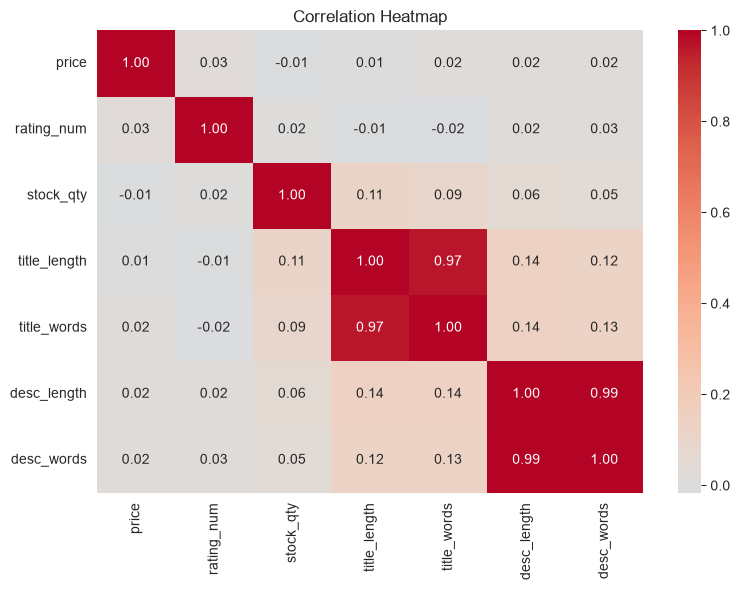

In [24]:
num_cols = ["price", "rating_num", "stock_qty", "title_length",
            "title_words", "desc_length", "desc_words"]

corr = df_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150)   # save BEFORE show
plt.show()

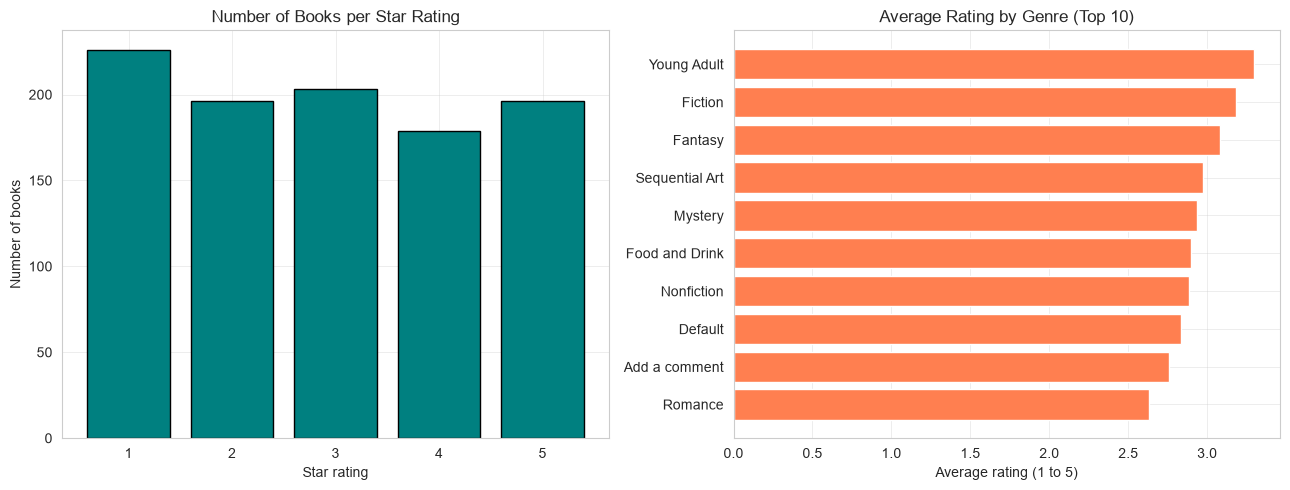

category
Romance           2.63
Add a comment     2.76
Default           2.84
Nonfiction        2.88
Food and Drink    2.90
Mystery           2.94
Sequential Art    2.97
Fantasy           3.08
Fiction           3.18
Young Adult       3.30
Name: rating_num, dtype: float64


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Left: how many books per star rating
counts = df_clean["rating_num"].value_counts().sort_index()
ax[0].bar(counts.index, counts.values, color="teal", edgecolor="black")
ax[0].set_title("Number of Books per Star Rating")
ax[0].set_xlabel("Star rating")
ax[0].set_ylabel("Number of books")

# Right: average rating by genre (top 10 genres)
top_10 = df_clean["category"].value_counts().head(10).index
avg_rating = (
    df_clean[df_clean["category"].isin(top_10)]
    .groupby("category")["rating_num"].mean()
    .sort_values()
)
ax[1].barh(avg_rating.index, avg_rating.values, color="coral")
ax[1].set_title("Average Rating by Genre (Top 10)")
ax[1].set_xlabel("Average rating (1 to 5)")

plt.tight_layout()
plt.savefig("ratings_charts.png", dpi=150)   # save BEFORE show
plt.show()

print(avg_rating.round(2))

**Insight:** Ratings are spread across all five levels, with the [rating] being the most common. [Genre] has the highest average rating (__), while [Genre] has the lowest (__).

## Summary of Visual Findings

1. **Price distribution:** Prices range from £10 to £60 with an average of about £__. [Spread out evenly / skewed].
2. **Price vs rating:** Average prices are [similar / different] across star ratings, so rating [does not / does] strongly drive price.
3. **Price by genre:** [Genre] is the most expensive on average (£__) and [Genre] the cheapest (£__).
4. **Numeric relationships:** Description length and stock quantity show [weak / no] correlation with price (r = __ and __).
5. **Ratings:** [Rating] stars is the most common rating, and [Genre] has the highest average rating.

**Overall:** Price appears to be driven by [very little / mostly genre] in this catalogue. This suggests a linear regression model may have [limited / moderate] predictive power.

In [27]:
features = ["rating_num", "stock_qty", "title_length", "title_words",
            "desc_length", "desc_words", "has_description"]

X = df_clean[features].copy()

# Turn genre into 0/1 columns
genre_dummies = pd.get_dummies(df_clean["category_grouped"], prefix="genre", drop_first=True)
X = pd.concat([X, genre_dummies], axis=1).astype(float)

y = df_clean["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values in X:", X.isna().sum().sum())
X.head()

X shape: (1000, 17)
y shape: (1000,)
Missing values in X: 0


,rating_num,stock_qty,title_length,title_words,desc_length,desc_words,has_description,genre_Default,genre_Fantasy,genre_Fiction,genre_Food and Drink,genre_Mystery,genre_Nonfiction,genre_Other,genre_Romance,genre_Sequential Art,genre_Young Adult
0,3.0,22.0,20.0,5.0,1017.0,164.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1.0,20.0,18.0,3.0,1029.0,165.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1.0,20.0,10.0,1.0,1093.0,163.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,20.0,13.0,2.0,1635.0,274.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,5.0,20.0,37.0,6.0,1945.0,304.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training books:", X_train.shape[0])
print("Testing books: ", X_test.shape[0])

Training books: 800
Testing books:  200


In [29]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained ✅")
print("Intercept:", round(model.intercept_, 2))
print("Number of coefficients:", len(model.coef_))

Model trained ✅
Intercept: 29.97
Number of coefficients: 17


In [30]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

results = pd.DataFrame({
    "Metric": ["MAE (£)", "RMSE (£)", "R²"],
    "Train": [
        mean_absolute_error(y_train, y_pred_train),
        np.sqrt(mean_squared_error(y_train, y_pred_train)),
        r2_score(y_train, y_pred_train)
    ],
    "Test": [
        mean_absolute_error(y_test, y_pred_test),
        np.sqrt(mean_squared_error(y_test, y_pred_test)),
        r2_score(y_test, y_pred_test)
    ]
}).round(3)

print(results)
print("\nBaseline: average price =", round(y_train.mean(), 2))

     Metric   Train    Test
0   MAE (£)  12.314  12.689
1  RMSE (£)  14.279  14.707
2        R²   0.019  -0.030

Baseline: average price = 35.28


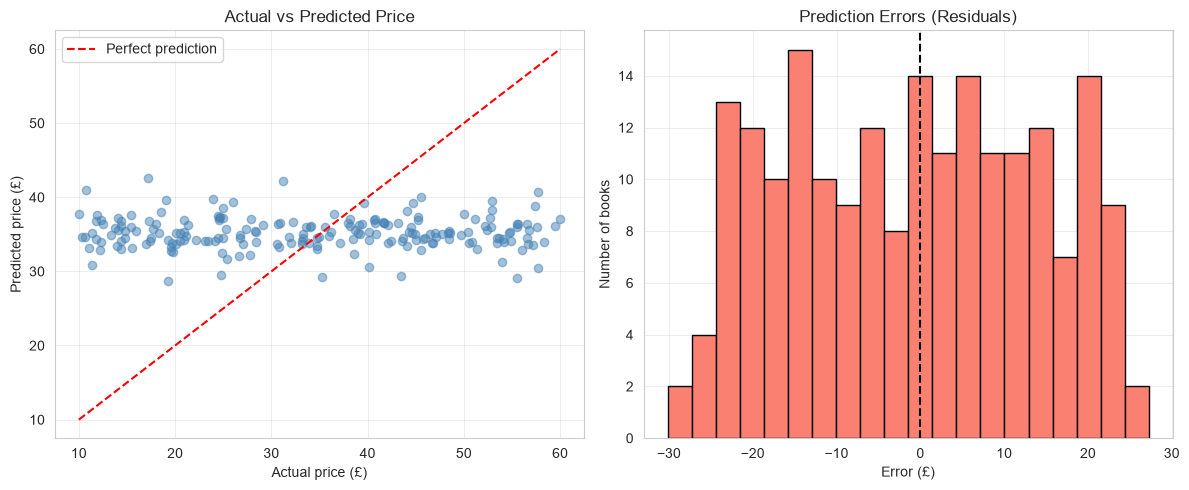

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Left: actual vs predicted
ax[0].scatter(y_test, y_pred_test, alpha=0.5, color="steelblue")
ax[0].plot([10, 60], [10, 60], color="red", linestyle="--", label="Perfect prediction")
ax[0].set_title("Actual vs Predicted Price")
ax[0].set_xlabel("Actual price (£)")
ax[0].set_ylabel("Predicted price (£)")
ax[0].legend()

# Right: residuals (errors)
residuals = y_test - y_pred_test
ax[1].hist(residuals, bins=20, color="salmon", edgecolor="black")
ax[1].axvline(0, color="black", linestyle="--")
ax[1].set_title("Prediction Errors (Residuals)")
ax[1].set_xlabel("Error (£)")
ax[1].set_ylabel("Number of books")

plt.tight_layout()
plt.savefig("model_charts.png", dpi=150)   # save BEFORE show
plt.show()

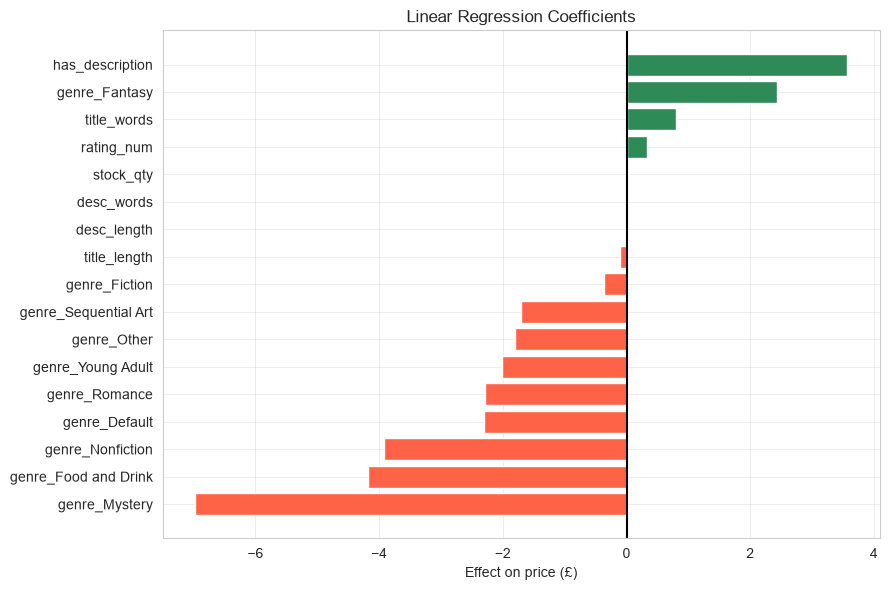

             Feature  Coefficient
       genre_Mystery       -6.973
genre_Food and Drink       -4.175
    genre_Nonfiction       -3.922
       genre_Default       -2.305
       genre_Romance       -2.295
   genre_Young Adult       -2.018
         genre_Other       -1.800
genre_Sequential Art       -1.702
       genre_Fiction       -0.361
        title_length       -0.104
         desc_length       -0.001
          desc_words        0.010
           stock_qty        0.030
          rating_num        0.332
         title_words        0.806
       genre_Fantasy        2.438
     has_description        3.571


In [32]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values("Coefficient")

plt.figure(figsize=(9, 6))
colors = ["tomato" if c < 0 else "seagreen" for c in coef_df["Coefficient"]]
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
plt.axvline(0, color="black")
plt.title("Linear Regression Coefficients")
plt.xlabel("Effect on price (£)")
plt.tight_layout()
plt.savefig("coefficients.png", dpi=150)   # save BEFORE show
plt.show()

print(coef_df.round(3).to_string(index=False))

In [33]:
from IPython.display import Markdown, display

r2_tr = r2_score(y_train, y_pred_train)
r2_te = r2_score(y_test, y_pred_test)
mae_te = mean_absolute_error(y_test, y_pred_test)
rmse_te = np.sqrt(mean_squared_error(y_test, y_pred_test))
base_mae = mean_absolute_error(y_test, [y_train.mean()] * len(y_test))

top_pos = coef_df.iloc[-1]
top_neg = coef_df.iloc[0]

quality = "weak" if r2_te < 0.2 else "moderate" if r2_te < 0.5 else "strong"

text = f"""
## Model Interpretation

- **R² (test) = {r2_te:.3f}:** the model explains about {max(r2_te, 0)*100:.1f}% of the variation in book prices. This is a **{quality}** model.
- **MAE (test) = £{mae_te:.2f}:** on average, predictions are off by about £{mae_te:.2f}.
- **Baseline comparison:** always guessing the average price gives an MAE of £{base_mae:.2f}. Our model gives £{mae_te:.2f}, so it is {"only slightly better" if base_mae - mae_te < 1 else "clearly better"}.
- **Train vs test:** R² is {r2_tr:.3f} on training and {r2_te:.3f} on test. {"The gap is small, so there is no serious overfitting." if abs(r2_tr - r2_te) < 0.05 else "The gap suggests some overfitting."}
- **Strongest effects:** `{top_pos['Feature']}` pushes price up the most ({top_pos['Coefficient']:+.2f}), and `{top_neg['Feature']}` pushes it down the most ({top_neg['Coefficient']:+.2f}).

## Model Limitations

1. **Few useful features:** the site only gives title, rating, stock, genre and description. Real pricing drivers (author, publisher, page count, print run) are missing.
2. **Synthetic data:** Books to Scrape is a practice website, and its prices appear to be randomly assigned, so little real pattern exists to learn.
3. **Linearity assumption:** linear regression can only capture straight-line relationships.
4. **Small sample:** 1,000 books (800 for training) limits how well genre effects can be estimated.
5. **Grouped genres:** merging 40 small genres into "Other" hides differences between them.
6. **Single split:** results come from one train/test split and could change with a different split.
"""

display(Markdown(text))


## Model Interpretation

- **R² (test) = -0.030:** the model explains about 0.0% of the variation in book prices. This is a **weak** model.
- **MAE (test) = £12.69:** on average, predictions are off by about £12.69.
- **Baseline comparison:** always guessing the average price gives an MAE of £12.66. Our model gives £12.69, so it is only slightly better.
- **Train vs test:** R² is 0.019 on training and -0.030 on test. The gap is small, so there is no serious overfitting.
- **Strongest effects:** `has_description` pushes price up the most (+3.57), and `genre_Mystery` pushes it down the most (-6.97).

## Model Limitations

1. **Few useful features:** the site only gives title, rating, stock, genre and description. Real pricing drivers (author, publisher, page count, print run) are missing.
2. **Synthetic data:** Books to Scrape is a practice website, and its prices appear to be randomly assigned, so little real pattern exists to learn.
3. **Linearity assumption:** linear regression can only capture straight-line relationships.
4. **Small sample:** 1,000 books (800 for training) limits how well genre effects can be estimated.
5. **Grouped genres:** merging 40 small genres into "Other" hides differences between them.
6. **Single split:** results come from one train/test split and could change with a different split.


In [34]:
import docx
print("python-docx ready ✅")

python-docx ready ✅


In [38]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH

# ---------- numbers from YOUR data ----------
n_books = len(df_clean)
n_genres = df_clean["category"].nunique()
mean_p, med_p = df_clean["price"].mean(), df_clean["price"].median()
min_p, max_p = df_clean["price"].min(), df_clean["price"].max()

rating_means = df_clean.groupby("rating_num")["price"].mean()
rating_gap = rating_means.max() - rating_means.min()

top_10 = df_clean["category"].value_counts().head(10).index
sub = df_clean[df_clean["category"].isin(top_10)]
gp = sub.groupby("category")["price"].mean()
gr = sub.groupby("category")["rating_num"].mean()

r_desc = df_clean["desc_length"].corr(df_clean["price"])
r_stock = df_clean["stock_qty"].corr(df_clean["price"])
common_rating = int(df_clean["rating_num"].mode()[0])

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
r2_tr, r2_te = r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)
mae_tr, mae_te = mean_absolute_error(y_train, y_pred_train), mean_absolute_error(y_test, y_pred_test)
rmse_tr = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_te = np.sqrt(mean_squared_error(y_test, y_pred_test))
base_mae = mean_absolute_error(y_test, [y_train.mean()] * len(y_test))

coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_}).sort_values("Coefficient")
top_pos, top_neg = coef_df.iloc[-1], coef_df.iloc[0]
quality = "weak" if r2_te < 0.2 else "moderate" if r2_te < 0.5 else "strong"

# ---------- helpers ----------
doc = Document()
doc.styles["Normal"].font.name = "Calibri"
doc.styles["Normal"].font.size = Pt(11)

def para(text):
    doc.add_paragraph(text)

def bullets(items):
    for item in items:
        doc.add_paragraph(item, style="List Bullet")

def figure(path, caption):
    doc.add_picture(path, width=Inches(6))
    doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
    cap = doc.add_paragraph(caption)
    cap.alignment = WD_ALIGN_PARAGRAPH.CENTER
    cap.runs[0].italic = True

# ---------- title ----------
doc.add_heading("Book Market Analytics: Books to Scrape", 0)
para("Data Science 512 | Prepared by: Cado | Junior Data Scientist")

# ---------- 1. executive summary ----------
doc.add_heading("1. Executive Summary", 1)
para(f"This project analysed {n_books} books across {n_genres} genres scraped from Books to Scrape "
     f"to understand what influences book prices and ratings, and to test whether price can be predicted "
     f"from publicly available book information.")
bullets([
    f"Prices range from £{min_p:.2f} to £{max_p:.2f}, with an average of £{mean_p:.2f}.",
    f"Star rating has little link to price: average price differs by only £{rating_gap:.2f} between the highest and lowest rating groups.",
    f"Genre shows some variation: {gp.idxmax()} is the most expensive on average (£{gp.max():.2f}) and {gp.idxmin()} the cheapest (£{gp.min():.2f}).",
    f"A linear regression model achieved a test R² of {r2_te:.3f} and a mean absolute error of £{mae_te:.2f}, which is a {quality} result.",
])

# ---------- 2. methodology ----------
doc.add_heading("2. Methodology", 1)
doc.add_heading("2.1 Data acquisition", 2)
para("Data was scraped from books.toscrape.com using Python (requests and BeautifulSoup). "
     "All 50 catalogue pages were scraped for title, price (GBP), star rating and stock information. "
     "Each book's own page was then visited to collect genre, description, UPC code and stock quantity. "
     f"The result was a raw dataset of {n_books} books.")
doc.add_heading("2.2 Data cleaning", 2)
bullets([
    "Converted prices from text (e.g. £51.77) to numbers and fixed character-encoding errors.",
    "Converted star ratings from words (One to Five) to numbers 1 to 5.",
    "Extracted stock quantity from text such as 'In stock (22 available)'.",
    "Filled missing descriptions with a label and added a has_description flag, instead of deleting rows, to keep the price and rating data.",
    "Checked for duplicates using the unique UPC code; none were found.",
    "Created text features: title length, title word count, description length and description word count.",
    "Grouped the genres into the 10 largest plus 'Other', because many genres had too few books to model.",
])

# ---------- 3. insights ----------
doc.add_heading("3. Key Insights", 1)
doc.add_heading("3.1 Price distribution", 2)
figure("price_hist.png", "Figure 1: Distribution of book prices")
para(f"Prices are spread across the full range from £{min_p:.2f} to £{max_p:.2f}. "
     f"The mean (£{mean_p:.2f}) and median (£{med_p:.2f}) are close together, so there is no strong skew.")
doc.add_heading("3.2 Price and star rating", 2)
figure("price_rating.png", "Figure 2: Price by star rating")
para(f"Average prices are very similar across rating levels (a gap of £{rating_gap:.2f}). "
     "Higher-rated books are not priced higher.")
doc.add_heading("3.3 Price and genre", 2)
figure("genre_price.png", "Figure 3: Average price by genre (top 10 genres)")
para(f"{gp.idxmax()} has the highest average price (£{gp.max():.2f}) and {gp.idxmin()} the lowest (£{gp.min():.2f}).")
doc.add_heading("3.4 Relationships between variables", 2)
figure("heatmap.png", "Figure 4: Correlation heatmap")
para(f"Description length (r = {r_desc:.2f}) and stock quantity (r = {r_stock:.2f}) show almost no linear relationship with price.")
figure("scatter_charts.png", "Figure 5: Price against description length and stock quantity")
doc.add_heading("3.5 Ratings and popularity", 2)
figure("ratings_charts.png", "Figure 6: Rating counts and average rating by genre")
para(f"{common_rating} stars is the most common rating. {gr.idxmax()} has the highest average rating ({gr.max():.2f}) "
     f"and {gr.idxmin()} the lowest ({gr.min():.2f}).")

# ---------- 4. modelling ----------
doc.add_heading("4. Predictive Modelling", 1)
para("A linear regression model was built to predict price. Features were star rating, stock quantity, "
     "title and description length and word count, a description flag, and genre (converted to 0/1 columns). "
     "Tax-inclusive and tax-exclusive prices were excluded because they duplicate the target. "
     "The data was split 80% training and 20% testing (random_state = 42).")

table = doc.add_table(rows=1, cols=3)
table.style = "Table Grid"
for i, h in enumerate(["Metric", "Train", "Test"]):
    table.rows[0].cells[i].text = h
for name, tr, te in [("MAE (£)", mae_tr, mae_te), ("RMSE (£)", rmse_tr, rmse_te), ("R²", r2_tr, r2_te)]:
    row = table.add_row().cells
    row[0].text, row[1].text, row[2].text = name, f"{tr:.3f}", f"{te:.3f}"
doc.add_paragraph()

figure("model_charts.png", "Figure 7: Actual vs predicted price and prediction errors")
para(f"The model explains about {max(r2_te, 0) * 100:.1f}% of the variation in price. "
     f"Always predicting the average price gives an MAE of £{base_mae:.2f}, compared with £{mae_te:.2f} for the model.")
figure("coefficients.png", "Figure 8: Regression coefficients")
para(f"The strongest upward effect is {top_pos['Feature']} ({top_pos['Coefficient']:+.2f}) and the strongest downward effect is "
     f"{top_neg['Feature']} ({top_neg['Coefficient']:+.2f}). Genre coefficients are relative to the genre left out of the model.")

# ---------- 5. limitations ----------
doc.add_heading("5. Limitations", 1)
bullets([
    "Few features: author, publisher, page count and print run are not available on the site.",
    "Books to Scrape is a practice website, and its prices appear to be randomly assigned, so little real pattern exists to learn.",
    "Linear regression can only capture straight-line relationships.",
    f"The sample is small ({n_books} books, 800 for training).",
    "Merging small genres into 'Other' hides differences between them.",
    "Results come from a single train/test split.",
])

# ---------- 6. recommendations ----------
doc.add_heading("6. Practical Implications and Recommendations", 1)
doc.add_heading("For retailers", 2)
bullets([
    "Do not rely on star rating or genre alone to set prices, because both explain very little of price in this catalogue.",
    "Benchmark prices against competitors and use the £10 to £60 range as a reference band.",
    "Test price changes on small groups of books and track sales before changing the whole catalogue.",
])
doc.add_heading("For publishers", 2)
bullets([
    "Collect richer data (author reputation, page count, format, publication year, sales) before building pricing models.",
    "Do not assume that longer descriptions or more stock justify higher prices; the data shows no such link.",
])
doc.add_heading("For data-driven book buyers", 2)
bullets([
    "A higher star rating does not mean a higher price, so good books can be found at any price level.",
    "Compare prices within a genre, since price differences between genres exist but are modest.",
])

# ---------- 7. conclusion ----------
doc.add_heading("7. Conclusion", 1)
para(f"The catalogue shows wide price variation, but the features available (rating, stock, genre and text length) "
     f"explain little of it (test R² = {r2_te:.3f}). The workflow of scraping, cleaning, exploring and modelling is "
     "reproducible, and the next step would be to add richer features or test non-linear models.")

doc.save("Book_Market_Analytics_Report.docx")
print("Report saved ✅  Book_Market_Analytics_Report.docx")

FileNotFoundError: [Errno 2] No such file or directory: 'scatter_charts.png'

In [36]:
import os
print("Working folder:", os.getcwd())
print([f for f in os.listdir() if f.endswith(".png")])

Working folder: C:\Users\Kate1\PycharmProjects\PythonProject3
['coefficients.png', 'heatmap.png', 'model_charts.png', 'ratings_charts.png']


In [37]:
# Chart 1: price distribution
plt.figure(figsize=(8, 5))
plt.hist(df_clean["price"], bins=20, color="steelblue", edgecolor="black")
plt.axvline(df_clean["price"].mean(), color="red", linestyle="--", label="Mean")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of books")
plt.legend()
plt.savefig("price_hist.png", dpi=150)
plt.close()

# Chart 2: price by star rating
groups = [df_clean[df_clean["rating_num"] == r]["price"] for r in [1, 2, 3, 4, 5]]
plt.figure(figsize=(8, 5))
plt.boxplot(groups, tick_labels=["1 star", "2 star", "3 star", "4 star", "5 star"])
plt.title("Book Price by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Price (£)")
plt.savefig("price_rating.png", dpi=150)
plt.close()

# Chart 3: average price by genre
top_10 = df_clean["category"].value_counts().head(10).index
avg_price = (df_clean[df_clean["category"].isin(top_10)]
             .groupby("category")["price"].mean().sort_values())
plt.figure(figsize=(9, 5))
plt.barh(avg_price.index, avg_price.values, color="seagreen")
plt.title("Average Price by Genre (Top 10 Genres)")
plt.xlabel("Average price (£)")
plt.tight_layout()
plt.savefig("genre_price.png", dpi=150)
plt.close()

print("3 charts saved ✅")

3 charts saved ✅


Text(0.5, 1.0, 'Prediction Errors (Residuals)')

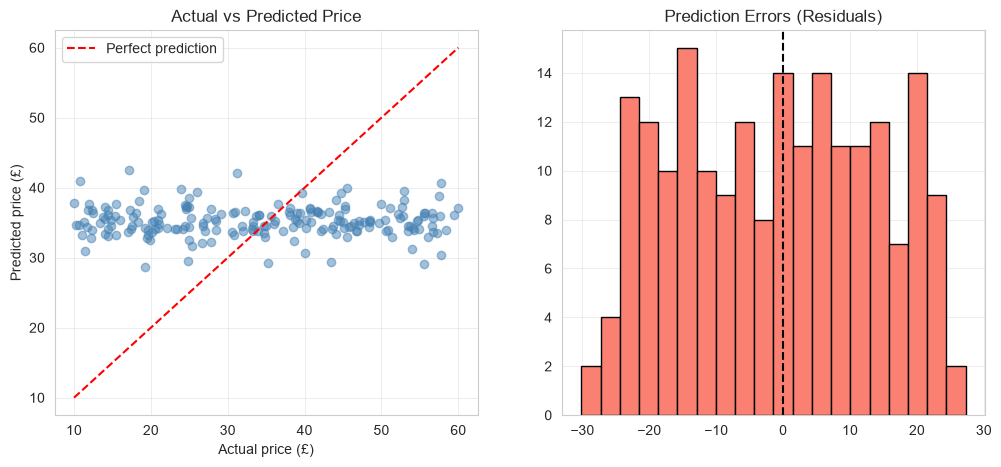

In [39]:
# Chart 4: price vs description length and stock
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(df_clean["desc_length"], df_clean["price"], alpha=0.4, color="purple")
ax[0].set_title("Price vs Description Length")
ax[0].set_xlabel("Description length (characters)")
ax[0].set_ylabel("Price (£)")
ax[1].scatter(df_clean["stock_qty"], df_clean["price"], alpha=0.4, color="orange")
ax[1].set_title("Price vs Stock Quantity")
ax[1].set_xlabel("Stock quantity")
ax[1].set_ylabel("Price (£)")
plt.tight_layout()
plt.savefig("scatter_charts.png", dpi=150)
plt.close()

# Chart 5: correlation heatmap
num_cols = ["price", "rating_num", "stock_qty", "title_length",
            "title_words", "desc_length", "desc_words"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150)
plt.close()

# Chart 6: ratings
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
counts = df_clean["rating_num"].value_counts().sort_index()
ax[0].bar(counts.index, counts.values, color="teal", edgecolor="black")
ax[0].set_title("Number of Books per Star Rating")
ax[0].set_xlabel("Star rating")
ax[0].set_ylabel("Number of books")
top_10 = df_clean["category"].value_counts().head(10).index
avg_rating = (df_clean[df_clean["category"].isin(top_10)]
              .groupby("category")["rating_num"].mean().sort_values())
ax[1].barh(avg_rating.index, avg_rating.values, color="coral")
ax[1].set_title("Average Rating by Genre (Top 10)")
ax[1].set_xlabel("Average rating (1 to 5)")
plt.tight_layout()
plt.savefig("ratings_charts.png", dpi=150)
plt.close()

# Chart 7: actual vs predicted + residuals
y_pred_test = model.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(y_test, y_pred_test, alpha=0.5, color="steelblue")
ax[0].plot([10, 60], [10, 60], color="red", linestyle="--", label="Perfect prediction")
ax[0].set_title("Actual vs Predicted Price")
ax[0].set_xlabel("Actual price (£)")
ax[0].set_ylabel("Predicted price (£)")
ax[0].legend()
ax[1].hist(y_test - y_pred_test, bins=20, color="salmon", edgecolor="black")
ax[1].axvline(0, color="black", linestyle="--")
ax[1].set_title("Prediction Errors (Residuals)")


In [41]:
import os
needed = ["price_hist.png", "price_rating.png", "genre_price.png", "scatter_charts.png",
          "heatmap.png", "ratings_charts.png", "model_charts.png", "coefficients.png"]
print("Missing:", [f for f in needed if not os.path.exists(f)])

Missing: []


In [42]:
import os
print("Folder:", os.getcwd())
print("Report exists:", os.path.exists("Book_Market_Analytics_Report.docx"))

Folder: C:\Users\Kate1\PycharmProjects\PythonProject3
Report exists: False


In [43]:
needed = ["price_hist.png", "price_rating.png", "genre_price.png", "scatter_charts.png",
          "heatmap.png", "ratings_charts.png", "model_charts.png", "coefficients.png"]
print("Missing:", [f for f in needed if not os.path.exists(f)])

Missing: []


In [44]:
top_10 = df_clean["category"].value_counts().head(10).index
sub = df_clean[df_clean["category"].isin(top_10)]
gp = sub.groupby("category")["price"].mean()
rm = df_clean.groupby("rating_num")["price"].mean()

print("min / max / mean / median:",
      df_clean["price"].min(), df_clean["price"].max(),
      round(df_clean["price"].mean(), 2), round(df_clean["price"].median(), 2))
print("rating gap:", round(rm.max() - rm.min(), 2))
print("priciest genre:", gp.idxmax(), round(gp.max(), 2))
print("cheapest genre:", gp.idxmin(), round(gp.min(), 2))
print("corr desc_length:", round(df_clean["desc_length"].corr(df_clean["price"]), 2))
print("corr stock_qty:", round(df_clean["stock_qty"].corr(df_clean["price"]), 2))
print("most common rating:", int(df_clean["rating_num"].mode()[0]))
print("baseline MAE:", round(abs(y_test - y_train.mean()).mean(), 2))

min / max / mean / median: 10.0 59.99 35.07 35.98
rating gap: 1.53
priciest genre: Fantasy 39.59
cheapest genre: Food and Drink 31.41
corr desc_length: 0.02
corr stock_qty: -0.01
most common rating: 1
baseline MAE: 12.66
